# Einführung in die digitale Signalverarbeitung – 1. Hausaufgabe

**Gruppe:** _A_ (bitte anpassen)

| Name | Matrikelnummer |
|------|----------------|
| Luca Steindorf | 553004 |
| William Anton Pogadl | _000000_ |
| Ben Tony Schulz | _000000_ |
| Melina Gehrling | _000000_ |

In [1]:
import timeit
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (10, 3.5)
plt.rcParams["axes.grid"] = True

## 1 Audiodateien importieren und darstellen
Die Dateien werden mit `scipy.io.wavfile.read` eingelesen. Stereosignale werden auf den ersten Kanal
reduziert, anschließend wird jedes Signal auf einen maximalen Absolutwert von 1 normiert.

In [2]:
def load_and_normalize(filename):
    # Datei einlesen: Abtastrate fs [Hz] und Samples
    fs, x = wavfile.read(filename)
    x = x.astype(float)            # int16 -> float, damit die Normierung exakt ist
    if x.ndim > 1:                 # Stereo (oder mehr Kanäle) -> nur ersten Kanal behalten
        x = x[:, 0]
    x = x / np.max(np.abs(x))      # Normierung auf max. Absolutamplitude 1
    return x, fs


speech, fs_speech = load_and_normalize("speech.wav")
ir, fs_ir = load_and_normalize("impulse_response.wav")

print(f"speech.wav:           fs = {fs_speech} Hz, {len(speech)} Samples, max|x| = {np.max(np.abs(speech))}")
print(f"impulse_response.wav: fs = {fs_ir} Hz, {len(ir)} Samples, max|x| = {np.max(np.abs(ir))}")

speech.wav:           fs = 44100 Hz, 487052 Samples, max|x| = 1.0
impulse_response.wav: fs = 44100 Hz, 198637 Samples, max|x| = 1.0


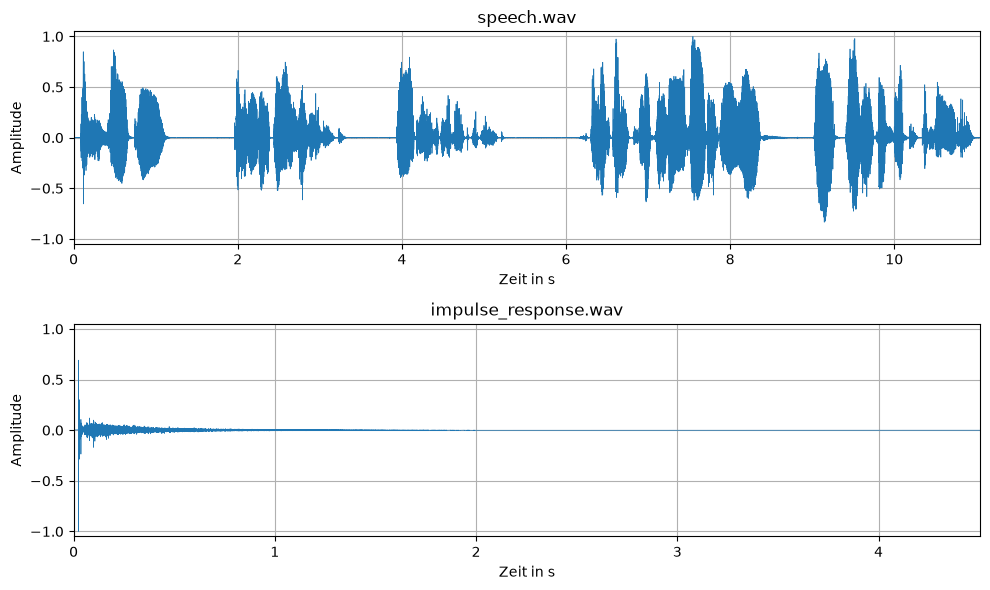

In [3]:
# Zeitachsen in Sekunden
t_speech = np.arange(len(speech)) / fs_speech
t_ir = np.arange(len(ir)) / fs_ir

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
for ax, t, x, name in zip(axes, [t_speech, t_ir], [speech, ir],
                          ["speech.wav", "impulse_response.wav"]):
    ax.plot(t, x, linewidth=0.5)
    ax.set_title(name)
    ax.set_xlabel("Zeit in s")
    ax.set_ylabel("Amplitude")
    ax.set_xlim(t[0], t[-1])
    ax.set_ylim(-1.05, 1.05)
plt.tight_layout()
plt.show()

## 2 Systemeigenschaften

Ein System $y[n] = \mathcal{T}\{x[n]\}$ wird auf folgende Eigenschaften geprüft:

* **Linearität:** $\mathcal{T}\{a x_1[n] + b x_2[n]\} = a\,\mathcal{T}\{x_1[n]\} + b\,\mathcal{T}\{x_2[n]\}$ für alle $a, b, x_1, x_2$.
* **Zeitinvarianz:** Für $x'[n] = x[n-n_0]$ muss gelten $\mathcal{T}\{x'[n]\} = y[n-n_0]$ für alle $n_0$.
* **Rekursivität:** Das System ist rekursiv, wenn der Ausgang von vergangenen Ausgangswerten $y[n-k]$ abhängt.
* **Kausalität:** $y[n]$ hängt nur von $x[m]$ mit $m \le n$ ab.
* **Gedächtnislosigkeit:** $y[n]$ hängt nur von $x[n]$ (zum selben Zeitpunkt) ab.

### System 1: $y_1[n] = 2\,x[n^2-1]$

**Linearität:** Mit $x[n] = a x_1[n] + b x_2[n]$:
$$
\mathcal{T}\{a x_1 + b x_2\}[n] = 2\big(a x_1[n^2-1] + b x_2[n^2-1]\big) = a\cdot 2x_1[n^2-1] + b\cdot 2x_2[n^2-1] = a\,y_{1,1}[n] + b\,y_{1,2}[n]
$$
$\Rightarrow$ **linear**.

**Zeitinvarianz:** Eingang verschoben, $x'[n] = x[n-n_0]$:
$$
\mathcal{T}\{x'\}[n] = 2\,x'[n^2-1] = 2\,x[n^2-1-n_0]
$$
Verschobener Ausgang:
$$
y_1[n-n_0] = 2\,x[(n-n_0)^2-1] = 2\,x[n^2 - 2nn_0 + n_0^2 - 1]
$$
Beide Ausdrücke sind für $n_0 \neq 0$ im Allgemeinen verschieden (z. B. $n_0=1$, $n=0$: $x[-2]$ vs. $x[0]$)
$\Rightarrow$ **zeitvariant**.

**Rekursivität:** $y_1[n]$ hängt nur von Eingangswerten ab, nicht von früheren Ausgangswerten $\Rightarrow$ **nicht rekursiv**.

**Kausalität:** Für $n = 2$ gilt $y_1[2] = 2x[3]$, d. h. der Ausgang hängt von einem zukünftigen Eingangswert ab
(allgemein ist $n^2-1 > n$ für $n \ge 2$ und $n \le -1$) $\Rightarrow$ **nicht kausal**.

**Gedächtnislosigkeit:** Für $n = 0$ gilt $y_1[0] = 2x[-1]$, also wird ein Eingangswert zu einem anderen Zeitpunkt
benötigt (Gleichheit $n^2-1 = n$ gilt für kein ganzzahliges $n$) $\Rightarrow$ **nicht gedächtnislos** (dynamisch).

### System 2: $y_2[n] = \sqrt{3}\,x[n] + x[n+2]$

**Linearität:**
$$
\mathcal{T}\{a x_1 + b x_2\}[n] = \sqrt{3}\big(a x_1[n] + b x_2[n]\big) + a x_1[n+2] + b x_2[n+2]
= a\big(\sqrt{3}x_1[n] + x_1[n+2]\big) + b\big(\sqrt{3}x_2[n] + x_2[n+2]\big) = a\,y_{2,1}[n] + b\,y_{2,2}[n]
$$
$\Rightarrow$ **linear**.

**Zeitinvarianz:** Mit $x'[n] = x[n-n_0]$:
$$
\mathcal{T}\{x'\}[n] = \sqrt{3}\,x[n-n_0] + x[n+2-n_0], \qquad
y_2[n-n_0] = \sqrt{3}\,x[n-n_0] + x[(n-n_0)+2]
$$
Beide Ausdrücke sind identisch $\Rightarrow$ **zeitinvariant**.

**Rekursivität:** Kein Term $y_2[n-k]$ auf der rechten Seite $\Rightarrow$ **nicht rekursiv** (FIR-System).

**Kausalität:** $y_2[n]$ hängt von $x[n+2]$ ab, also von einem zukünftigen Wert $\Rightarrow$ **nicht kausal**.

**Gedächtnislosigkeit:** Wegen $x[n+2]$ hängt $y_2[n]$ nicht nur vom aktuellen Eingangswert ab $\Rightarrow$ **nicht gedächtnislos**.

### Zusammenfassung

| | linear | zeitinvariant | rekursiv | kausal | gedächtnislos |
|---|---|---|---|---|---|
| $y_1[n] = 2x[n^2-1]$ | ja | nein | nein | nein | nein |
| $y_2[n] = \sqrt{3}x[n] + x[n+2]$ | ja | ja | nein | nein | nein |

## 3 Faltung

$$y[n] = 0.2\,\big(x[n+2] + x[n+1] + x[n] + x[n-1] + x[n-2]\big)$$

### a) Kausales System und Impulsantwort

Das System greift auf bis zu zwei zukünftige Werte zu ($x[n+2]$). Durch eine Verzögerung des Ausgangs um
2 Samples ($n \rightarrow n-2$) wird es kausal:
$$
y_\text{c}[n] = y[n-2] = 0.2\,\big(x[n] + x[n-1] + x[n-2] + x[n-3] + x[n-4]\big)
$$
Die Impulsantwort ergibt sich mit $x[n] = \delta[n]$:
$$
h[n] = 0.2\,\big(\delta[n] + \delta[n-1] + \delta[n-2] + \delta[n-3] + \delta[n-4]\big)
= \begin{cases} 0.2, & 0 \le n \le 4 \\ 0, & \text{sonst} \end{cases}
$$
also $h = [0.2,\ 0.2,\ 0.2,\ 0.2,\ 0.2]$ – ein gleitender Mittelwert (Moving Average) über 5 Samples.

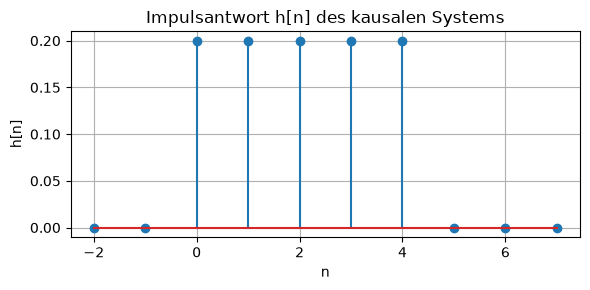

In [5]:
# Impulsantwort des kausalen Systems (gleitender Mittelwert über 5 Samples)
h = 0.2 * np.ones(5)

fig, ax = plt.subplots(figsize=(6, 3))
ax.stem(np.arange(-2, 8), np.concatenate(([0, 0], h, [0, 0, 0])))
ax.set_title("Impulsantwort h[n] des kausalen Systems")
ax.set_xlabel("n")
ax.set_ylabel("h[n]")
plt.tight_layout()
plt.show()

### b) Eigene Faltungsfunktion

Diskrete Faltung zweier endlicher Folgen der Längen $N_a$ und $N_b$:
$$
c[n] = (a * b)[n] = \sum_{k=0}^{N_a-1} a[k]\, b[n-k], \qquad n = 0, \dots, N_a + N_b - 2
$$

In [6]:
def convolve(a, b):
    # Diskrete (lineare) Faltung c = a * b ohne Drittanbieter-Faltungsfunktionen.
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    Na, Nb = len(a), len(b)
    c = np.zeros(Na + Nb - 1)          # Länge des Faltungsergebnisses
    for n in range(Na + Nb - 1):        # jedes Ausgangssample
        for k in range(Na):             # Summe über a[k] * b[n-k]
            if 0 <= n - k < Nb:         # nur gültige Indizes von b verwenden
                c[n] += a[k] * b[n - k]
    return c


# Verifikation mit dem vorgegebenen Beispiel
result = convolve([1, -1], [2, 0, 0, 1])
print("convolve([1, -1], [2, 0, 0, 1]) =", result)
np.testing.assert_allclose(result, [2, -2, 0, 1, -1])
print("Test bestanden: Ergebnis entspricht [2, -2, 0, 1, -1]")

convolve([1, -1], [2, 0, 0, 1]) = [ 2. -2.  0.  1. -1.]
Test bestanden: Ergebnis entspricht [2, -2, 0, 1, -1]


### c) Faltung von Sinussignalen

Zwei Sinussignale mit 16 Samples Länge, $f_s = 16$ kHz und Frequenzen von 1 kHz bzw. 4 kHz werden mit $h[n]$ gefaltet.

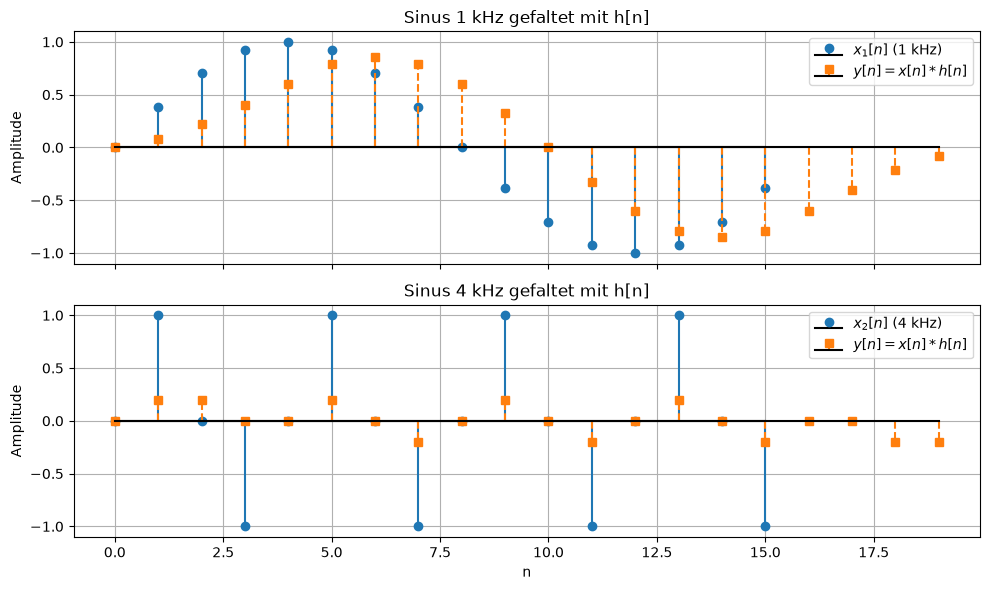

In [7]:
fs = 16000                     # Abtastrate in Hz
N = 16                         # Länge in Samples
n = np.arange(N)               # Sample-Index

x1 = np.sin(2 * np.pi * 1000 * n / fs)   # 1 kHz
x2 = np.sin(2 * np.pi * 4000 * n / fs)   # 4 kHz

y1 = convolve(x1, h)           # Länge 16 + 5 - 1 = 20
y2 = convolve(x2, h)
n_y = np.arange(len(y1))

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, x, y, f in zip(axes, [x1, x2], [y1, y2], [1, 4]):
    ax.stem(n, x, linefmt="C0-", markerfmt="C0o", basefmt="k-", label=f"$x_{{{1 if f == 1 else 2}}}[n]$ ({f} kHz)")
    ax.stem(n_y, y, linefmt="C1--", markerfmt="C1s", basefmt="k-", label="$y[n] = x[n] * h[n]$")
    ax.set_title(f"Sinus {f} kHz gefaltet mit h[n]")
    ax.set_ylabel("Amplitude")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("n")
plt.tight_layout()
plt.show()

### d) Verhalten des Systems

Das System bildet den **gleitenden Mittelwert** über 5 aufeinanderfolgende Samples und wirkt damit als
**Tiefpassfilter** (FIR-Filter mit 5 Koeffizienten). Der Frequenzgang lautet
$$
H(e^{j\Omega}) = 0.2 \sum_{n=0}^{4} e^{-j\Omega n}
= 0.2\,\frac{\sin(5\Omega/2)}{\sin(\Omega/2)}\, e^{-j2\Omega}, \qquad \Omega = 2\pi f / f_s .
$$

Auswirkungen auf die Zeitsignale:

* **Amplitude:** Tiefe Frequenzen werden kaum gedämpft, hohe stark. Für 1 kHz ergibt sich
  $|H| = 0.2\,\sin(5\pi/16)/\sin(\pi/16) \approx 0.85$, für 4 kHz nur $|H| = 0.2$. Bei 4 kHz (Periode 4 Samples)
  heben sich vier der fünf Samples im Mittelwert gegenseitig auf, sodass nur ein Fünftel eines Samples übrig bleibt.
  Zusätzlich wechselt das Vorzeichen von $H$ bei 4 kHz ($\sin(5\pi/4) < 0$), d. h. das Signal ist dort gegenüber
  der reinen Verzögerung invertiert.
* **Verzögerung:** Durch das Kausalmachen besitzt das System eine lineare Phase mit einer konstanten
  Gruppenlaufzeit von 2 Samples (= 125 µs); die Ausgangssignale sind gegenüber dem Eingang um 2 Samples verschoben.
* **Ein- und Ausschwingen:** Da die Eingangssignale nur 16 Samples lang sind, ist das Ergebnis $16+5-1 = 20$ Samples lang.
  In den ersten 4 Samples ist das Filter noch nicht vollständig mit Signal „gefüllt“ (Einschwingen), in den letzten
  4 Samples läuft es aus (Ausschwingen). Nur dazwischen (n = 4 … 15) liegt der stationäre Zustand vor, in dem der Ausgang
  ein sinusförmiges Signal derselben Frequenz mit veränderter Amplitude und Phase ist.
* Das System glättet also das Signal: langsame Änderungen bleiben erhalten, schnelle Änderungen werden geglättet.

In [8]:
# Numerische Bestätigung der Amplitudenfaktoren aus dem stationären Bereich (n = 4 ... 15)
for f, x, y in [(1000, x1, y1), (4000, x2, y2)]:
    Omega = 2 * np.pi * f / fs
    H = 0.2 * np.sum(np.exp(-1j * Omega * np.arange(5)))
    ratio = np.max(np.abs(y[4:16])) / np.max(np.abs(x))
    print(f"f = {f} Hz: |H| (theoretisch) = {np.abs(H):.3f}, Max-Verhältnis Ausgang/Eingang im stationären Bereich = {ratio:.3f}")

f = 1000 Hz: |H| (theoretisch) = 0.852, Max-Verhältnis Ausgang/Eingang im stationären Bereich = 0.852
f = 4000 Hz: |H| (theoretisch) = 0.200, Max-Verhältnis Ausgang/Eingang im stationären Bereich = 0.200


### e) Kommutativität und Distributivität

Es wird numerisch gezeigt:

1. Kommutativgesetz: $x_1[n] * h[n] = h[n] * x_1[n]$
2. Distributivgesetz: $(x_1[n] * h[n]) + (x_2[n] * h[n]) = (x_1[n] + x_2[n]) * h[n]$

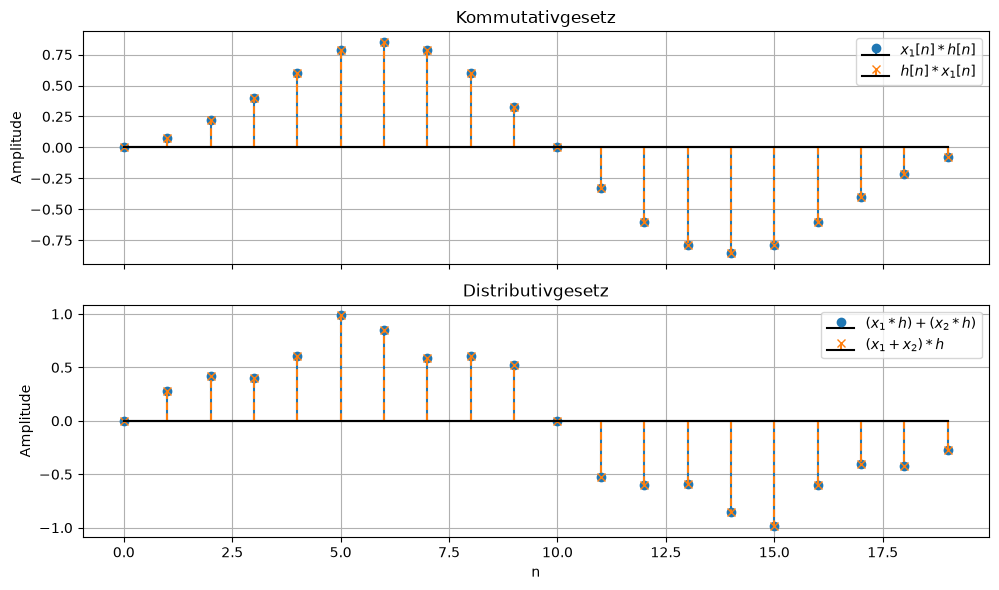

max. Abweichung Kommutativität:   2.220446049250313e-16
max. Abweichung Distributivität:  2.220446049250313e-16


In [9]:
# 1) Kommutativität
y_xh = convolve(x1, h)
y_hx = convolve(h, x1)

# 2) Distributivität
y_left = convolve(x1, h) + convolve(x2, h)
y_right = convolve(x1 + x2, h)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].stem(n_y, y_xh, linefmt="C0-", markerfmt="C0o", basefmt="k-", label="$x_1[n] * h[n]$")
axes[0].stem(n_y, y_hx, linefmt="C1--", markerfmt="C1x", basefmt="k-", label="$h[n] * x_1[n]$")
axes[0].set_title("Kommutativgesetz")
axes[1].stem(n_y, y_left, linefmt="C0-", markerfmt="C0o", basefmt="k-", label="$(x_1 * h) + (x_2 * h)$")
axes[1].stem(n_y, y_right, linefmt="C1--", markerfmt="C1x", basefmt="k-", label="$(x_1 + x_2) * h$")
axes[1].set_title("Distributivgesetz")
for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("n")
plt.tight_layout()
plt.show()

# Numerischer Nachweis (bis auf Rundungsfehler identisch)
np.testing.assert_allclose(y_xh, y_hx, atol=1e-12)
np.testing.assert_allclose(y_left, y_right, atol=1e-12)
print("max. Abweichung Kommutativität:  ", np.max(np.abs(y_xh - y_hx)))
print("max. Abweichung Distributivität: ", np.max(np.abs(y_left - y_right)))

Beide Gleichungen gelten (Abweichungen nur im Bereich der Gleitkomma-Genauigkeit). Die Kommutativität folgt aus der
Substitution $m = n-k$ in der Faltungssumme, die Distributivität aus der Linearität der Summe:
$\sum_k (x_1[k]+x_2[k])\,h[n-k] = \sum_k x_1[k]\,h[n-k] + \sum_k x_2[k]\,h[n-k]$.

## 4 Implementierung der Diskreten Fourier-Transformation

Die DFT eines reellen Signals der Länge $N$ lautet
$$
X[k] = \sum_{n=0}^{N-1} x[n]\, e^{-j 2\pi k n / N}, \qquad k = 0, \dots, N-1 .
$$
Für reelle Signale gilt $X[N-k] = X^*[k]$, daher genügt das einseitige Spektrum mit $k = 0, \dots, N/\!/2$.
Die zugehörigen Frequenzen sind $f_k = k\, f_s / N$.

Die Implementierung erfolgt als Matrix-Vektor-Produkt: die Matrix $W_{k,n} = e^{-j2\pi kn/N}$ wird mit numpy
aufgebaut (kein FFT-Modul).

In [10]:
def rdft(x, fs):
    # Einseitiges Spektrum X (k = 0 ... N//2) und Frequenzvektor f in Hz eines reellen Signals x.
    x = np.asarray(x, dtype=float)
    N = len(x)
    k = np.arange(N // 2 + 1)                   # Frequenz-Indizes bis zum Symmetriepunkt
    n = np.arange(N)                            # Zeit-Indizes
    W = np.exp(-2j * np.pi * np.outer(k, n) / N)  # DFT-Matrix (N//2+1) x N
    X = W @ x                                   # X[k] = sum_n x[n] e^{-j 2 pi k n / N}
    f = k * fs / N                              # zugehörige Frequenzen in Hz
    return X, f

### a) + b) Vergleich mit `numpy.fft.rfft` / `numpy.fft.rfftfreq`
Für jede Länge $N$ wird Rauschen erzeugt, die Ergebnisse werden mit `numpy.testing.assert_allclose`
(Standardtoleranzen) verglichen und die Rechenzeiten für jeweils 5 Durchläufe mit `timeit.timeit` gemessen.

In [11]:
fs = 44100
rng = np.random.default_rng(seed=1)

print(f"{'N':>6} | {'Ergebnis identisch':>18} | {'t rdft (5x) in s':>16} | {'t numpy (5x) in s':>17} | {'Faktor':>8}")
print("-" * 78)
for N in [1024, 1025, 1026, 1027, 4096, 8192]:
    x = rng.standard_normal(N)                     # Rauschsignal der Länge N

    # a) Vergleich der Ergebnisse
    X, f = rdft(x, fs)
    X_np = np.fft.rfft(x)
    f_np = np.fft.rfftfreq(N, d=1 / fs)
    np.testing.assert_allclose(X, X_np)            # Spektrum
    np.testing.assert_allclose(f, f_np)            # Frequenzvektor

    # b) Vergleich der Rechenzeiten (5 Wiederholungen)
    t_own = timeit.timeit("rdft(x, fs)", number=5, globals={"rdft": rdft, "x": x, "fs": fs})
    t_np = timeit.timeit("np.fft.rfft(x); np.fft.rfftfreq(len(x), 1/fs)", number=5,
                         globals={"np": np, "x": x, "fs": fs})
    print(f"{N:>6} | {'ja':>18} | {t_own:>16.6f} | {t_np:>17.6f} | {t_own / t_np:>8.0f}")

     N | Ergebnis identisch | t rdft (5x) in s | t numpy (5x) in s |   Faktor
------------------------------------------------------------------------------
  1024 |                 ja |         0.038785 |          0.000070 |      557
  1025 |                 ja |         0.029856 |          0.000075 |      397
  1026 |                 ja |         0.026829 |          0.000054 |      494
  1027 |                 ja |         0.026115 |          0.000060 |      439
  4096 |                 ja |         0.410017 |          0.000099 |     4150
  8192 |                 ja |         1.659536 |          0.000167 |     9947


**Ergebnis:** Die Spektren und Frequenzvektoren stimmen für alle Längen (gerade und ungerade $N$) im Rahmen der
Standardtoleranzen von `assert_allclose` überein.

Die eigene Implementierung ist jedoch um Größenordnungen langsamer. Die direkte DFT benötigt
$\mathcal{O}(N^2)$ Operationen (hier ca. $N \cdot (N/2+1)$ komplexe Multiplikationen plus das Aufstellen der
Matrix), während die FFT mit $\mathcal{O}(N \log N)$ auskommt. Entsprechend wächst die Rechenzeit der eigenen
Funktion bei Verdopplung von $N$ etwa um den Faktor 4, die der FFT nur etwa um den Faktor 2.
Auffällig ist außerdem, dass die FFT für Zweierpotenzen ($N = 1024, 4096, 8192$) besonders effizient ist; für
$N = 1025, 1026, 1027$ (insbesondere Primzahl-Faktoren) ist sie relativ betrachtet langsamer, bleibt aber
deutlich schneller als die direkte DFT.

## 5 Zeitliches Aliasing
Zwei Sinussignale mit $f = 15$ kHz werden mit $f_s = 16$ kHz und $f_s = 192$ kHz abgetastet und für die erste
Millisekunde dargestellt.

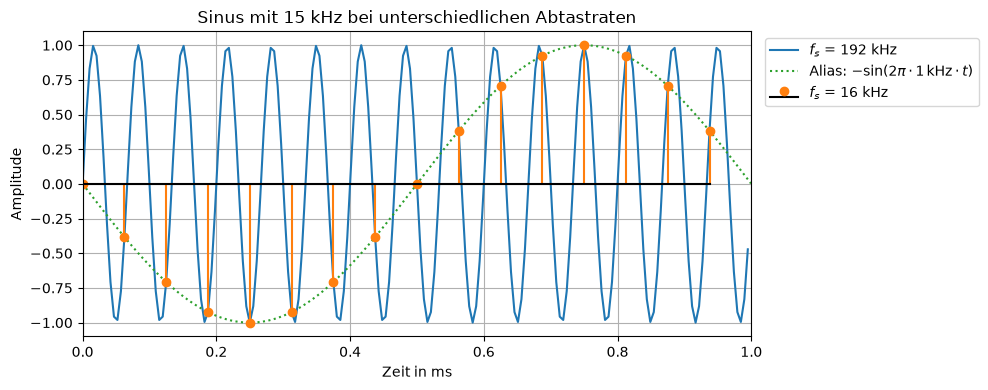

In [12]:
f0 = 15000                      # Frequenz des Sinus in Hz
T = 1e-3                        # Dauer: 1 ms

fs_low, fs_high = 16000, 192000
t_low = np.arange(int(T * fs_low)) / fs_low       # 16 Samples
t_high = np.arange(int(T * fs_high)) / fs_high    # 192 Samples

x_low = np.sin(2 * np.pi * f0 * t_low)
x_high = np.sin(2 * np.pi * f0 * t_high)

# Zum Vergleich: der 1-kHz-Alias (invertiert), den die 16-kHz-Abtastwerte tatsächlich beschreiben
t_fine = np.linspace(0, T, 2000, endpoint=False)
x_alias = -np.sin(2 * np.pi * (fs_low - f0) * t_fine)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(t_high * 1e3, x_high, "C0-", label="$f_s$ = 192 kHz")
ax.plot(t_fine * 1e3, x_alias, "C2:", label="Alias: $-\\sin(2\\pi \\cdot 1\\,\\mathrm{kHz} \\cdot t)$")
ax.stem(t_low * 1e3, x_low, linefmt="C1-", markerfmt="C1o", basefmt="k-", label="$f_s$ = 16 kHz")
ax.set_title("Sinus mit 15 kHz bei unterschiedlichen Abtastraten")
ax.set_xlabel("Zeit in ms")
ax.set_ylabel("Amplitude")
ax.set_xlim(0, 1)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Erklärung:**
Nach dem Abtasttheorem muss die Abtastrate mehr als doppelt so groß wie die höchste Signalfrequenz sein,
$f_s > 2 f$. Bei $f_s = 192$ kHz ist dies erfüllt ($f_\text{Nyquist} = 96$ kHz $> 15$ kHz), der Sinus wird korrekt
wiedergegeben. Bei $f_s = 16$ kHz liegt die Nyquist-Frequenz bei 8 kHz; der 15-kHz-Ton liegt darüber und das
Abtasttheorem ist verletzt.

Das abgetastete Signal ist mathematisch nicht von einem Ton mit einer anderen Frequenz zu unterscheiden:
$$
x[n] = \sin\!\left(2\pi \frac{15}{16} n\right) = \sin\!\left(2\pi n - 2\pi \frac{1}{16} n\right)
= -\sin\!\left(2\pi \frac{1}{16} n\right),
$$
da $\sin(2\pi n - \varphi) = -\sin(\varphi)$ für ganzzahlige $n$. Die Abtastwerte beschreiben also einen
**1-kHz-Sinus mit invertierter Phase** ($|f - f_s| = |15 - 16|$ kHz $= 1$ kHz). Zwischen zwei Abtastwerten
durchläuft der 15-kHz-Sinus fast eine ganze Periode ($15/16$), sodass jeder neue Abtastwert nur um $-1/16$
Periode „weiterrückt“. Die Frequenz wird an der Nyquist-Frequenz in den Basisband-Bereich $[0, f_s/2]$
gespiegelt – das ist zeitliches Aliasing. In der Abbildung liegen die orangefarbenen Abtastwerte genau auf der
grün gepunkteten 1-kHz-Kurve, die in der ersten Millisekunde genau eine Periode durchläuft.